In [1]:
import os
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================================
# CHANGE THIS PATH
# ============================================================

DATASET_DIR = Path("LoveDA")

# Example:
# DATASET_DIR = Path(r"C:\Users\YourName\Downloads\LoveDA")

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found:\n{DATASET_DIR}\n\n"
        "Please change DATASET_DIR to the correct LoveDA folder."
    )

print("Dataset found:")
print(DATASET_DIR)

Dataset found:
LoveDA


In [3]:
def print_folder_structure(folder, max_depth=3, current_depth=0):
    folder = Path(folder)

    if current_depth > max_depth:
        return

    indent = "    " * current_depth

    if current_depth == 0:
        print(f"📁 {folder.name}/")

    try:
        items = sorted(folder.iterdir(), key=lambda x: (x.is_file(), x.name.lower()))
    except PermissionError:
        print(indent + "    [Permission denied]")
        return

    for item in items:
        if item.is_dir():
            print(f"{indent}📁 {item.name}/")
            print_folder_structure(
                item,
                max_depth=max_depth,
                current_depth=current_depth + 1
            )
        else:
            print(f"{indent}📄 {item.name}")


print_folder_structure(DATASET_DIR, max_depth=3)

📁 LoveDA/
📁 Test/
    📁 Test/
        📁 Rural/
            📁 images_png/
        📁 Urban/
            📁 images_png/
📁 Train/
    📁 Train/
        📁 Rural/
            📁 images_png/
            📁 masks_png/
        📁 Urban/
            📁 images_png/
            📁 masks_png/
📁 Val/
    📁 Val/
        📁 Rural/
            📁 images_png/
            📁 masks_png/
        📁 Urban/
            📁 images_png/
            📁 masks_png/


In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
MASK_KEYWORDS = ["mask", "masks", "label", "labels", "annotation", "annotations"]
IMAGE_KEYWORDS = ["image", "images", "img"]

all_dirs = [p for p in DATASET_DIR.rglob("*") if p.is_dir()]

mask_dirs = []
image_dirs = []

for folder in all_dirs:
    name = folder.name.lower()

    if any(keyword in name for keyword in MASK_KEYWORDS):
        mask_dirs.append(folder)

    if any(keyword in name for keyword in IMAGE_KEYWORDS):
        image_dirs.append(folder)

print("Candidate IMAGE folders:")
for folder in image_dirs:
    print("  ", folder)

print("\nCandidate MASK folders:")
for folder in mask_dirs:
    print("  ", folder)

Candidate IMAGE folders:
   LoveDA\Test\Test\Rural\images_png
   LoveDA\Test\Test\Urban\images_png
   LoveDA\Train\Train\Rural\images_png
   LoveDA\Train\Train\Urban\images_png
   LoveDA\Val\Val\Rural\images_png
   LoveDA\Val\Val\Urban\images_png

Candidate MASK folders:
   LoveDA\Train\Train\Rural\masks_png
   LoveDA\Train\Train\Urban\masks_png
   LoveDA\Val\Val\Rural\masks_png
   LoveDA\Val\Val\Urban\masks_png


In [5]:
def get_image_files(folder):
    folder = Path(folder)

    return sorted([
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])


# Collect all image files from the entire dataset
all_image_files = get_image_files(DATASET_DIR)

# Separate likely masks from normal images
all_mask_files = []

for file in all_image_files:
    path_lower = str(file).lower()

    if any(keyword in path_lower for keyword in MASK_KEYWORDS):
        all_mask_files.append(file)

all_normal_images = [
    file for file in all_image_files
    if file not in set(all_mask_files)
]

print("Total image-like files:", len(all_image_files))
print("Likely image files:", len(all_normal_images))
print("Likely mask files:", len(all_mask_files))

Total image-like files: 10178
Likely image files: 5987
Likely mask files: 4191


In [6]:
def create_filename_dict(files):
    result = {}

    for file in files:
        # filename without extension
        stem = file.stem.lower()
        result[stem] = file

    return result


image_dict = create_filename_dict(all_normal_images)
mask_dict = create_filename_dict(all_mask_files)

image_names = set(image_dict.keys())
mask_names = set(mask_dict.keys())

matching_names = image_names.intersection(mask_names)

images_without_masks = image_names - mask_names
masks_without_images = mask_names - image_names

print("Number of images:", len(image_names))
print("Number of masks:", len(mask_names))
print("Matching filenames:", len(matching_names))
print("Images without masks:", len(images_without_masks))
print("Masks without images:", len(masks_without_images))

Number of images: 5987
Number of masks: 4191
Matching filenames: 4191
Images without masks: 1796
Masks without images: 0


In [7]:
print("=" * 60)
print("IMAGES WITHOUT MATCHING MASKS")
print("=" * 60)

for name in sorted(images_without_masks)[:30]:
    print(image_dict[name])

if len(images_without_masks) > 30:
    print(f"... and {len(images_without_masks) - 30} more")


print("\n" + "=" * 60)
print("MASKS WITHOUT MATCHING IMAGES")
print("=" * 60)

for name in sorted(masks_without_images)[:30]:
    print(mask_dict[name])

if len(masks_without_images) > 30:
    print(f"... and {len(masks_without_images) - 30} more")

IMAGES WITHOUT MATCHING MASKS
LoveDA\Test\Test\Rural\images_png\4191.png
LoveDA\Test\Test\Rural\images_png\4192.png
LoveDA\Test\Test\Rural\images_png\4193.png
LoveDA\Test\Test\Rural\images_png\4194.png
LoveDA\Test\Test\Rural\images_png\4195.png
LoveDA\Test\Test\Rural\images_png\4196.png
LoveDA\Test\Test\Rural\images_png\4197.png
LoveDA\Test\Test\Rural\images_png\4198.png
LoveDA\Test\Test\Rural\images_png\4199.png
LoveDA\Test\Test\Rural\images_png\4200.png
LoveDA\Test\Test\Rural\images_png\4201.png
LoveDA\Test\Test\Rural\images_png\4202.png
LoveDA\Test\Test\Rural\images_png\4203.png
LoveDA\Test\Test\Rural\images_png\4204.png
LoveDA\Test\Test\Rural\images_png\4205.png
LoveDA\Test\Test\Rural\images_png\4206.png
LoveDA\Test\Test\Rural\images_png\4207.png
LoveDA\Test\Test\Rural\images_png\4208.png
LoveDA\Test\Test\Rural\images_png\4209.png
LoveDA\Test\Test\Rural\images_png\4210.png
LoveDA\Test\Test\Rural\images_png\4211.png
LoveDA\Test\Test\Rural\images_png\4212.png
LoveDA\Test\Test\Rural\i

In [8]:
image_size_counter = Counter()

corrupted_images = []

for file in all_normal_images:
    try:
        with Image.open(file) as img:
            image_size_counter[img.size] += 1

    except Exception as e:
        corrupted_images.append((file, str(e)))


print("Unique image dimensions:")
for size, count in image_size_counter.most_common():
    print(f"{size}: {count} images")

print("\nCorrupted/unreadable images:", len(corrupted_images))

Unique image dimensions:
(1024, 1024): 5987 images

Corrupted/unreadable images: 0


In [9]:
mask_size_counter = Counter()

corrupted_masks = []

for file in all_mask_files:
    try:
        with Image.open(file) as mask:
            mask_size_counter[mask.size] += 1

    except Exception as e:
        corrupted_masks.append((file, str(e)))


print("Unique mask dimensions:")
for size, count in mask_size_counter.most_common():
    print(f"{size}: {count} masks")

print("\nCorrupted/unreadable masks:", len(corrupted_masks))

Unique mask dimensions:
(1024, 1024): 4191 masks

Corrupted/unreadable masks: 0


In [10]:
dimension_mismatches = []

for name in sorted(matching_names):

    image_path = image_dict[name]
    mask_path = mask_dict[name]

    try:
        with Image.open(image_path) as img:
            image_size = img.size

        with Image.open(mask_path) as mask:
            mask_size = mask.size

        if image_size != mask_size:
            dimension_mismatches.append(
                {
                    "filename": name,
                    "image_size": image_size,
                    "mask_size": mask_size
                }
            )

    except Exception:
        pass


print("Image-mask dimension mismatches:", len(dimension_mismatches))

if dimension_mismatches:
    display(pd.DataFrame(dimension_mismatches).head(20))
else:
    print("All matched image-mask pairs have the same dimensions.")

Image-mask dimension mismatches: 0
All matched image-mask pairs have the same dimensions.


In [11]:
all_class_ids = set()

mask_class_counts = Counter()

for name in sorted(matching_names):

    mask_path = mask_dict[name]

    try:
        with Image.open(mask_path) as mask:
            mask_array = np.array(mask)

        unique_values, counts = np.unique(
            mask_array,
            return_counts=True
        )

        for value, count in zip(unique_values, counts):
            all_class_ids.add(int(value))
            mask_class_counts[int(value)] += int(count)

    except Exception as e:
        print("Error:", mask_path, e)


print("Unique class IDs found in masks:")
print(sorted(all_class_ids))

print("\nNumber of unique class IDs:", len(all_class_ids))

Unique class IDs found in masks:
[0, 1, 2, 3, 4, 5, 6, 7]

Number of unique class IDs: 8


In [12]:
class_distribution = pd.DataFrame(
    {
        "Class_ID": sorted(mask_class_counts.keys()),
        "Pixel_Count": [
            mask_class_counts[class_id]
            for class_id in sorted(mask_class_counts.keys())
        ]
    }
)

total_pixels = class_distribution["Pixel_Count"].sum()

class_distribution["Percentage"] = (
    class_distribution["Pixel_Count"] / total_pixels * 100
)

display(class_distribution)

,Class_ID,Pixel_Count,Percentage
0,0,145409132,3.308827
1,1,1525959012,34.723644
2,2,404299316,9.199949
3,3,213710339,4.863041
4,4,362297559,8.244187
5,5,207131990,4.713349
6,6,534690631,12.167042
7,7,1001084037,22.779960


In [13]:
print("=" * 60)
print("CORRUPTED IMAGE FILES")
print("=" * 60)

if corrupted_images:
    for file, error in corrupted_images[:20]:
        print(file)
        print("   Error:", error)
else:
    print("No corrupted image files detected.")


print("\n" + "=" * 60)
print("CORRUPTED MASK FILES")
print("=" * 60)

if corrupted_masks:
    for file, error in corrupted_masks[:20]:
        print(file)
        print("   Error:", error)
else:
    print("No corrupted mask files detected.")

CORRUPTED IMAGE FILES
No corrupted image files detected.

CORRUPTED MASK FILES
No corrupted mask files detected.


In [14]:
if len(matching_names) == 0:
    raise ValueError("No matching image-mask pairs found.")

sample_name = sorted(matching_names)[0]

image_path = image_dict[sample_name]
mask_path = mask_dict[sample_name]

image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path))

print("Sample:", sample_name)
print("Image:", image.shape)
print("Mask:", mask.shape)

Sample: 0
Image: (1024, 1024, 3)
Mask: (1024, 1024)


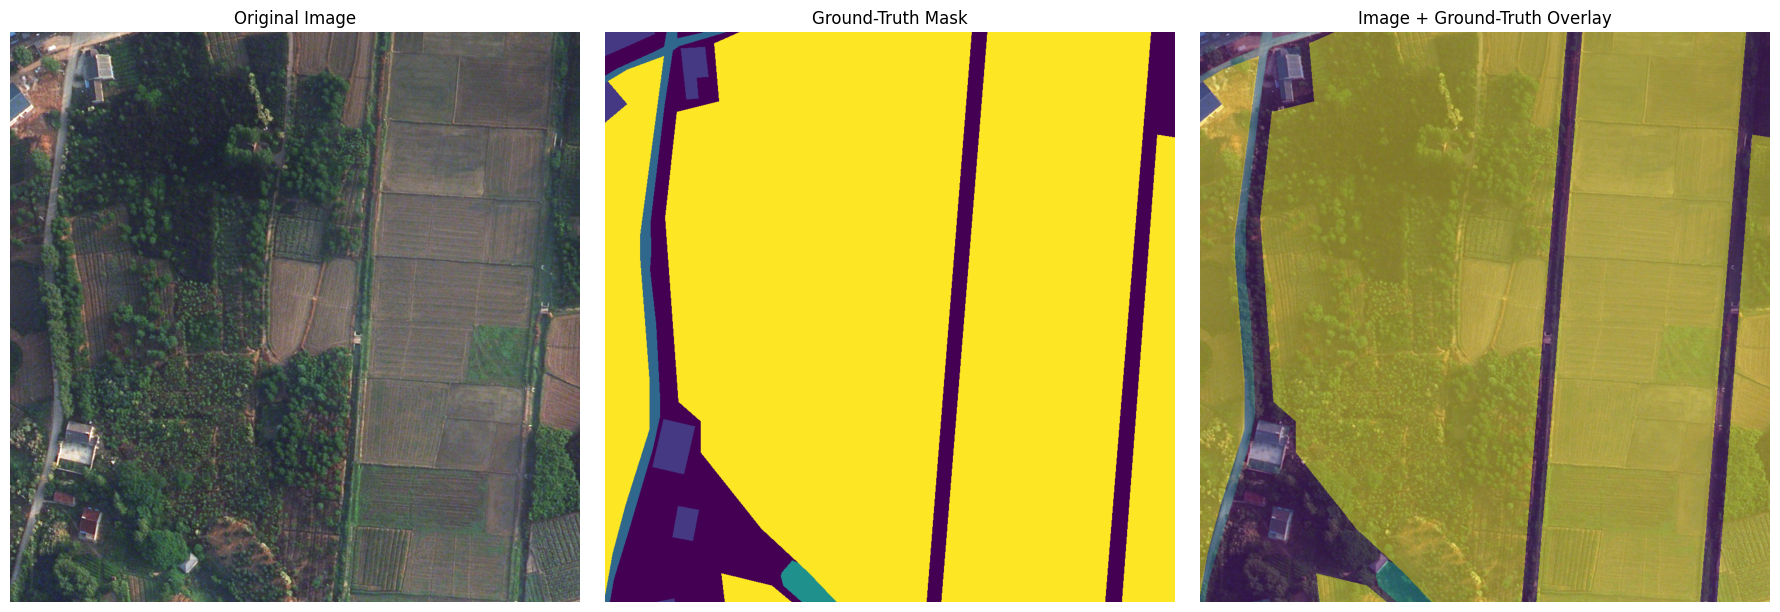

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Original image
axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

# Raw ground-truth mask
axes[1].imshow(mask)
axes[1].set_title("Ground-Truth Mask")
axes[1].axis("off")

# Overlay
axes[2].imshow(image)
axes[2].imshow(mask, alpha=0.45)
axes[2].set_title("Image + Ground-Truth Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

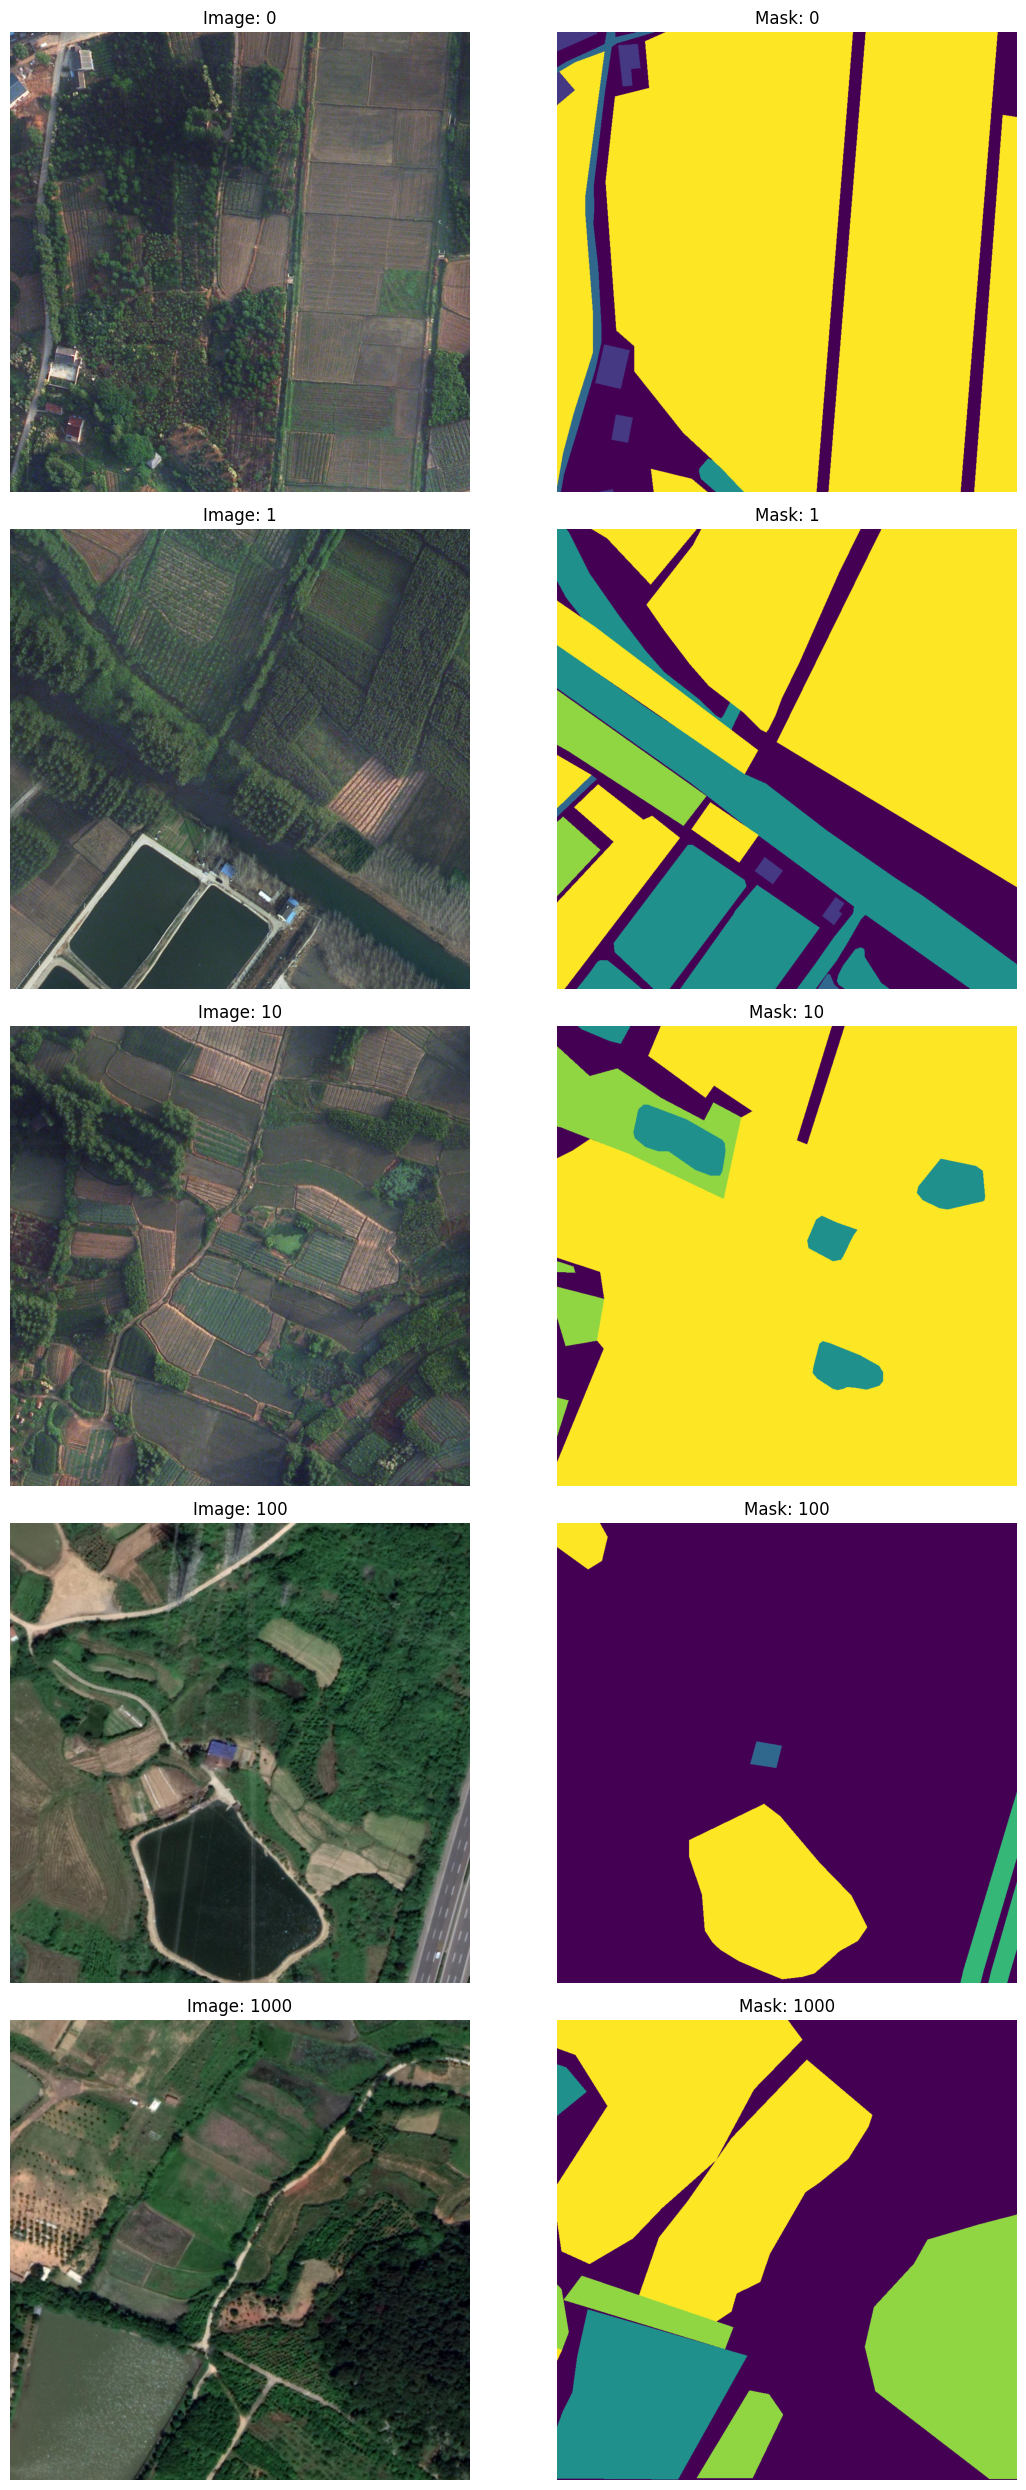

In [16]:
sample_names = sorted(matching_names)[:5]

fig, axes = plt.subplots(
    len(sample_names),
    2,
    figsize=(12, 5 * len(sample_names))
)

if len(sample_names) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, name in enumerate(sample_names):

    img = np.array(
        Image.open(image_dict[name]).convert("RGB")
    )

    msk = np.array(
        Image.open(mask_dict[name])
    )

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"Image: {name}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(msk)
    axes[row, 1].set_title(f"Mask: {name}")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [17]:
summary = {
    "Dataset path": str(DATASET_DIR),
    "Total image files": len(all_normal_images),
    "Total mask files": len(all_mask_files),
    "Matching image-mask pairs": len(matching_names),
    "Images without masks": len(images_without_masks),
    "Masks without images": len(masks_without_images),
    "Corrupted images": len(corrupted_images),
    "Corrupted masks": len(corrupted_masks),
    "Image-mask dimension mismatches": len(dimension_mismatches),
    "Number of unique mask classes": len(all_class_ids),
    "Unique class IDs": sorted(all_class_ids),
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Check", "Result"]
)

display(summary_df)

,Check,Result
0,Dataset path,LoveDA
1,Total image files,5987
2,Total mask files,4191
3,Matching image-mask pairs,4191
4,Images without masks,1796
5,Masks without images,0
6,Corrupted images,0
7,Corrupted masks,0
8,Image-mask dimension mismatches,0
9,Number of unique mask classes,8


In [18]:
REPORT_DIR = DATASET_DIR / "verification_report"
REPORT_DIR.mkdir(exist_ok=True)

summary_df.to_csv(
    REPORT_DIR / "dataset_summary.csv",
    index=False
)

class_distribution.to_csv(
    REPORT_DIR / "class_distribution.csv",
    index=False
)

if dimension_mismatches:
    pd.DataFrame(dimension_mismatches).to_csv(
        REPORT_DIR / "dimension_mismatches.csv",
        index=False
    )

print("Verification reports saved to:")
print(REPORT_DIR)

Verification reports saved to:
LoveDA\verification_report


In [19]:
print("=" * 70)
print("LOVE-DA DATASET VERIFICATION STATUS")
print("=" * 70)

checks = {
    "Images found": len(all_normal_images) > 0,
    "Masks found": len(all_mask_files) > 0,
    "Image-mask pairs found": len(matching_names) > 0,
    "No images without masks": len(images_without_masks) == 0,
    "No masks without images": len(masks_without_images) == 0,
    "No corrupted images": len(corrupted_images) == 0,
    "No corrupted masks": len(corrupted_masks) == 0,
    "No dimension mismatches": len(dimension_mismatches) == 0,
    "Multiple/valid class IDs detected": len(all_class_ids) > 1
}

for check, status in checks.items():
    print(f"{'✓' if status else '✗'} {check}")

print("=" * 70)

if all(checks.values()):
    print("DATASET VERIFICATION PASSED")
    print("We can proceed to preprocessing and model development.")
else:
    print("DATASET VERIFICATION NEEDS ATTENTION")
    print("Fix the failed checks before starting model training.")

LOVE-DA DATASET VERIFICATION STATUS
✓ Images found
✓ Masks found
✓ Image-mask pairs found
✗ No images without masks
✓ No masks without images
✓ No corrupted images
✓ No corrupted masks
✓ No dimension mismatches
✓ Multiple/valid class IDs detected
DATASET VERIFICATION NEEDS ATTENTION
Fix the failed checks before starting model training.
